# Week 1: Enterprise Sales & Revenue Analysis Dashboard
**Data Analytics Internship Capstone Project**  
*Author:* Data Analytics Intern  
*Dataset Period:* FY 2024 – FY 2026 (Multi-Year Corporate Transactions)  
*Objective:* Perform end-to-end Exploratory Data Analysis (EDA), KPI tracking, financial metric computation, and interactive business visualization.

---

### Key Business Metrics & KPIs:
- **Net Revenue & Gross Sales**: Revenue realization post-discount
- **Operating Profit & Margin %**: Gross vs Net margin across product lines
- **Average Order Value (AOV)** & **Average Revenue Per Customer (ARPC)**
- **Geographic & Customer Segment Performance**: Territory market share
- **Discount Elasticity & Profitability Impact**: Evaluating margin cannibalization


In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Visual configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('Libraries loaded successfully!')

Libraries loaded successfully!


## 1. Data Ingestion (CSV & Excel Multi-Source Loading)
Demonstrating multi-format data ingestion capabilities.

In [2]:
# Load raw CSV dataset
csv_path = '../data/raw/sales_data.csv'
df_raw = pd.read_csv(csv_path)

print(f'Total Raw Transactions Loaded: {len(df_raw):,}')
df_raw.head()

Total Raw Transactions Loaded: 3,500


,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,Region,State,City,Postal_Code,Product_ID,Category,Sub_Category,Product_Name,Unit_Cost,Unit_Price,Quantity,Discount_Rate,Gross_Sales,Discount_Amount,Revenue,COGS,Profit,Profit_Margin_Pct,Payment_Method,Order_Status
0,ORD-10279,2024-01-01,2024-01-05,Second Class,CUST-1406,Amelia White,Consumer,United States,Central,Texas,Austin,73301,FUR-OF-770,Furniture,Office Chairs,Herman Miller Aeron Ergonomic Chair,850.00,1395.00,1,0.00,1395.00,0.00,1395.00,850.00,545.00,39.07,Corporate ACH,Delivered
1,ORD-10391,2024-01-01,2024-01-05,Second Class,CUST-1260,Emily Lopez,Consumer,United States,Central,Michigan,Detroit,48201,TEC-AU-119,Technology,Audio & Video,Sony WH-1000XM5 Noise Canceling Headphones,220.00,398.00,2,0.00,796.00,0.00,796.00,440.00,356.00,44.72,Credit Card,Delivered
2,ORD-11225,2024-01-01,2024-01-03,Second Class,CUST-1241,Daniel Lopez,Consumer,United States,Central,Illinois,Chicago,60601,TEC-PE-430,Technology,Peripherals & Accessories,Keychron Q3 Pro Mechanical Keyboard,110.00,189.00,2,0.10,378.00,37.80,340.20,220.00,120.20,35.33,Credit Card,Delivered
3,ORD-12184,2024-01-01,2024-01-04,Standard Class,CUST-1280,Ava Hernandez,Consumer,United States,South,Florida,Miami,33101,FUR-ST-935,Furniture,Storage & Bookcases,Bush Furniture Cabot 5-Shelf Bookcase,110.00,219.00,5,0.10,1095.00,109.50,985.50,550.00,435.50,44.19,PayPal,Delivered
4,ORD-11536,2024-01-01,2024-01-04,Second Class,CUST-1179,Ella Rao,Home Office,United States,Central,Texas,Houston,77001,OFF-DE-669,Office Supplies,Desk Organization,Mind Reader Mesh Desk Organizer Caddy,9.50,22.99,1,0.05,22.99,1.15,21.84,9.50,12.34,56.50,Credit Card,Delivered


## 2. Data Cleaning & Integrity Auditing
Validating missing values, data types, and structural integrity.

In [3]:
# Data types and null check
print('--- Dataset Info & Null Counts ---')
print(df_raw.isnull().sum())

# Ensure datetime conversions
df = df_raw.copy()
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'])

# Temporal features
df['Year'] = df['Order_Date'].dt.year
df['Quarter'] = 'Q' + df['Order_Date'].dt.quarter.astype(str)
df['YearMonth'] = df['Order_Date'].dt.strftime('%Y-%m')
df['Month_Name'] = df['Order_Date'].dt.strftime('%b')
df['Days_to_Ship'] = (df['Ship_Date'] - df['Order_Date']).dt.days

print(f'\nShape after processing: {df.shape}')
df.describe()

--- Dataset Info & Null Counts ---
Order_ID             0
Order_Date           0
Ship_Date            0
Ship_Mode            0
Customer_ID          0
Customer_Name        0
Segment              0
Country              0
Region               0
State                0
City                 0
Postal_Code          0
Product_ID           0
Category             0
Sub_Category         0
Product_Name         0
Unit_Cost            0
Unit_Price           0
Quantity             0
Discount_Rate        0
Gross_Sales          0
Discount_Amount      0
Revenue              0
COGS                 0
Profit               0
Profit_Margin_Pct    0
Payment_Method       0
Order_Status         0
dtype: int64

Shape after processing: (3500, 33)


,Order_Date,Ship_Date,Postal_Code,Unit_Cost,Unit_Price,Quantity,Discount_Rate,Gross_Sales,Discount_Amount,Revenue,COGS,Profit,Profit_Margin_Pct,Year,Days_to_Ship
count,3500,3500,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00,3500.00
mean,2025-05-30 15:42:59.657142,2025-06-02 17:06:30.857142,51395.43,379.65,604.54,2.82,0.05,1702.13,87.96,1614.17,1067.38,546.78,38.96,2024.94,3.06
min,2024-01-01 00:00:00,2024-01-02 00:00:00,2108.00,8.50,18.99,1.00,0.00,18.99,0.00,15.19,8.50,-2.80,-0.04,2024.00,1.00
25%,2024-09-30 00:00:00,2024-10-03 18:00:00,28202.00,55.00,99.99,1.00,0.00,189.00,0.00,177.50,104.00,69.98,34.73,2024.00,2.00
50%,2025-06-05 00:00:00,2025-06-08 12:00:00,48201.00,280.00,499.00,2.00,0.00,829.00,0.00,760.00,460.00,269.97,39.47,2025.00,3.00
75%,2026-02-03 00:00:00,2026-02-06 00:00:00,77001.00,620.00,950.00,4.00,0.10,2398.00,57.00,2189.20,1400.00,712.00,44.70,2026.00,4.00
max,2026-10-15 00:00:00,2026-10-20 00:00:00,98101.00,1750.00,2499.00,14.00,0.30,27489.00,4260.00,27489.00,19250.00,8239.00,58.68,2026.00,7.00
std,NaN,NaN,32107.60,402.83,595.61,2.15,0.07,2391.15,250.74,2282.45,1581.41,742.20,9.10,0.79,1.36


## 3. Core KPI Calculation (DAX / Business Measures)
Calculating executive financial measures: Net Revenue, Net Profit, Profit Margin %, AOV, and YoY Growth.

In [4]:
total_revenue = df['Revenue'].sum()
total_gross = df['Gross_Sales'].sum()
total_cogs = df['COGS'].sum()
total_profit = df['Profit'].sum()
overall_margin = (total_profit / total_revenue) * 100
total_orders = df['Order_ID'].nunique()
total_customers = df['Customer_ID'].nunique()
total_units = df['Quantity'].sum()
aov = total_revenue / total_orders
arpc = total_revenue / total_customers

# Full Year YoY Comparison (2024 vs 2025)
rev_2024 = df[df['Year'] == 2024]['Revenue'].sum()
rev_2025 = df[df['Year'] == 2025]['Revenue'].sum()
yoy_growth = ((rev_2025 - rev_2024) / rev_2024) * 100

print('==================================================')
print('           EXECUTIVE KPI SCORECARD                ')
print('==================================================')
print(f'Total Net Revenue         : ')
print(f'Total Gross Sales         : ')
print(f'Total Cost of Goods (COGS): ')
print(f'Total Operating Profit    : ')
print(f'Net Profit Margin         : {overall_margin:.2f}%')
print(f'YoY Revenue Growth Rate   : {yoy_growth:.2f}%')
print(f'Total Unique Orders       : {total_orders:,}')
print(f'Total Unique Customers    : {total_customers:,}')
print(f'Total Units Sold          : {total_units:,}')
print(f'Average Order Value (AOV) : ')
print(f'Avg Revenue Per Customer  : ')
print('==================================================')

           EXECUTIVE KPI SCORECARD                
Total Net Revenue         : 
Total Gross Sales         : 
Total Cost of Goods (COGS): 
Total Operating Profit    : 
Net Profit Margin         : 33.87%
YoY Revenue Growth Rate   : 17.65%
Total Unique Orders       : 3,500
Total Unique Customers    : 450
Total Units Sold          : 9,874
Average Order Value (AOV) : 
Avg Revenue Per Customer  : 


## 4. Monthly Financial Trajectory & Seasonality Analysis

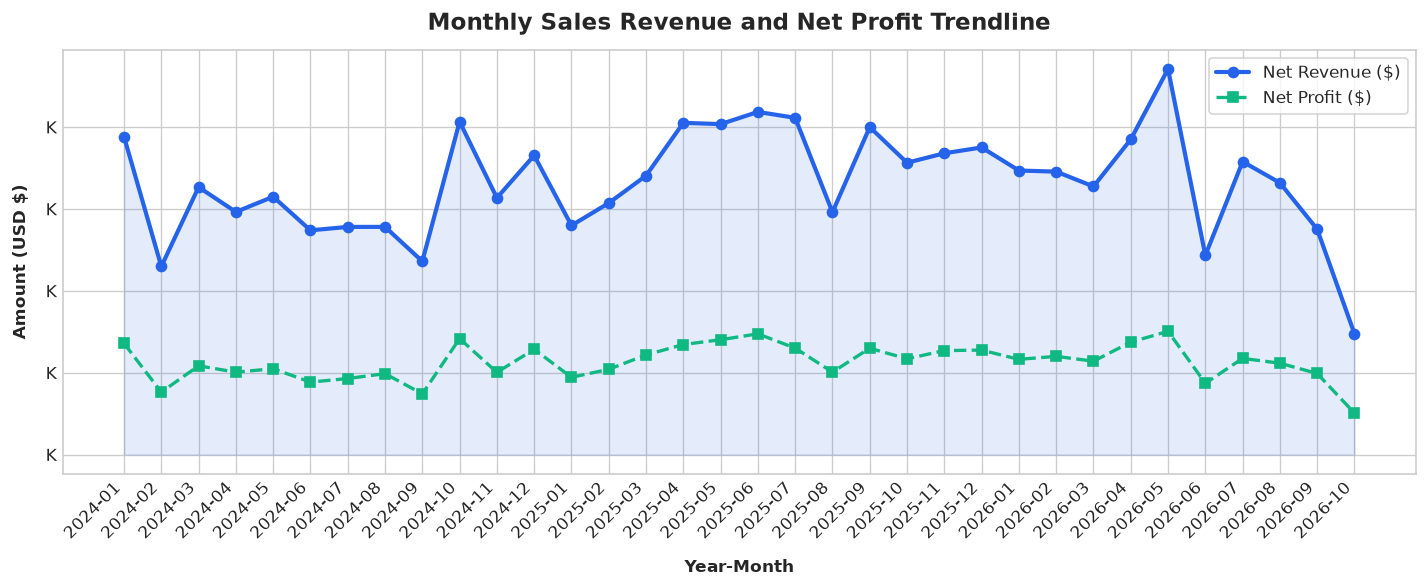

In [5]:
monthly_summary = df.groupby('YearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum')
).reset_index()

plt.figure(figsize=(12, 5))
plt.plot(monthly_summary['YearMonth'], monthly_summary['Revenue'], marker='o', color='#2563EB', linewidth=2.5, label='Net Revenue ($)')
plt.plot(monthly_summary['YearMonth'], monthly_summary['Profit'], marker='s', color='#10B981', linewidth=2, linestyle='--', label='Net Profit ($)')
plt.fill_between(range(len(monthly_summary)), monthly_summary['Revenue'], alpha=0.12, color='#2563EB')

plt.title('Monthly Sales Revenue and Net Profit Trendline', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Year-Month', fontweight='bold', labelpad=10)
plt.ylabel('Amount (USD $)', fontweight='bold', labelpad=10)
plt.xticks(range(len(monthly_summary)), monthly_summary['YearMonth'], rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'K'))
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

## 5. Category & Subcategory Profitability Breakdown

,Category,Revenue,Profit,Units,Margin_%
2,Technology,3706724.13,1159879.13,4159,31.29
0,Furniture,1795649.40,692404.40,2955,38.56
1,Office Supplies,147204.73,61451.23,2760,41.75


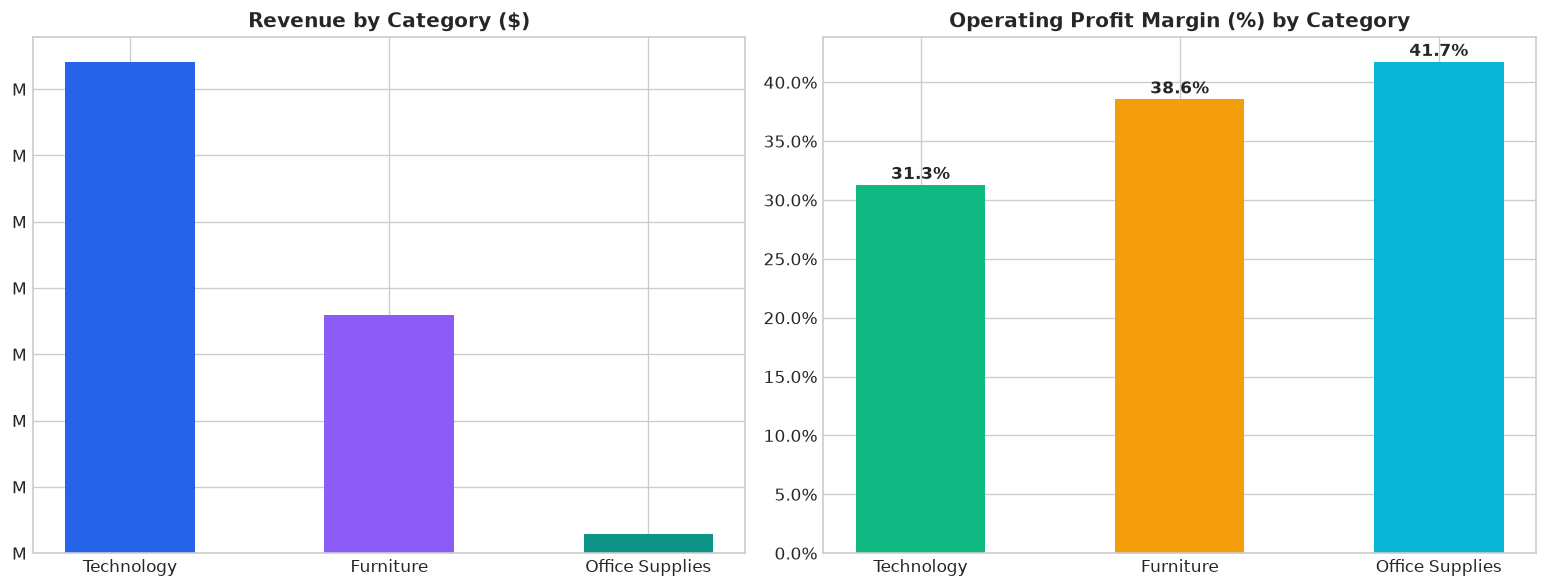

In [6]:
cat_summary = df.groupby('Category').agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Units=('Quantity', 'sum')
).reset_index().sort_values('Revenue', ascending=False)
cat_summary['Margin_%'] = (cat_summary['Profit'] / cat_summary['Revenue']) * 100

display(cat_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Revenue by Category
bars1 = ax1.bar(cat_summary['Category'], cat_summary['Revenue'], color=['#2563EB', '#8B5CF6', '#0D9488'], width=0.5)
ax1.set_title('Revenue by Category ($)', fontweight='bold', fontsize=12)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'M'))

# Margin % by Category
bars2 = ax2.bar(cat_summary['Category'], cat_summary['Margin_%'], color=['#10B981', '#F59E0B', '#06B6D4'], width=0.5)
ax2.set_title('Operating Profit Margin (%) by Category', fontweight='bold', fontsize=12)
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())

for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f'{b.get_height():.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Top 10 Best-Selling Products by Revenue Contribution

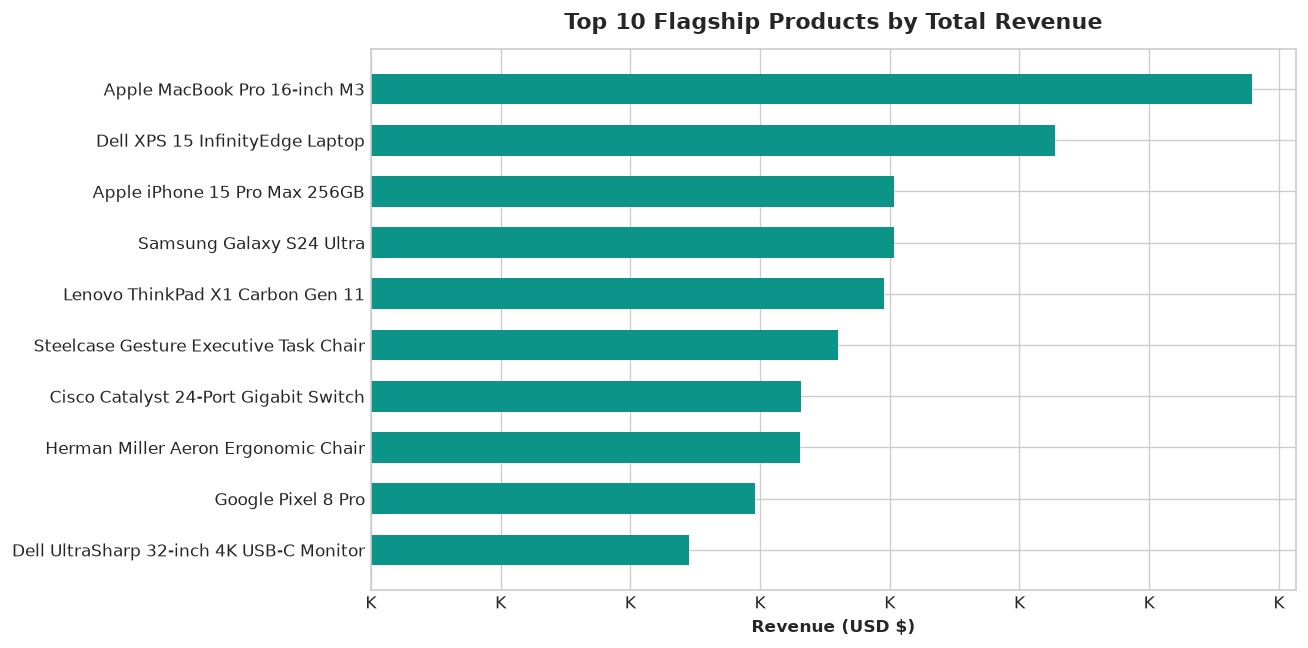

In [7]:
top_10_prods = df.groupby(['Product_Name', 'Category']).agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Units_Sold=('Quantity', 'sum')
).reset_index().sort_values('Revenue', ascending=False).head(10)

plt.figure(figsize=(11, 5.5))
bars = plt.barh(top_10_prods['Product_Name'][::-1], top_10_prods['Revenue'][::-1], color='#0D9488', height=0.6)
plt.title('Top 10 Flagship Products by Total Revenue', fontweight='bold', fontsize=13, pad=12)
plt.xlabel('Revenue (USD $)', fontweight='bold')
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'K'))

for b in bars:
    w = b.get_width()
    plt.text(w + 3000, b.get_y() + b.get_height()/2, f'', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Geographic Performance & Market Share

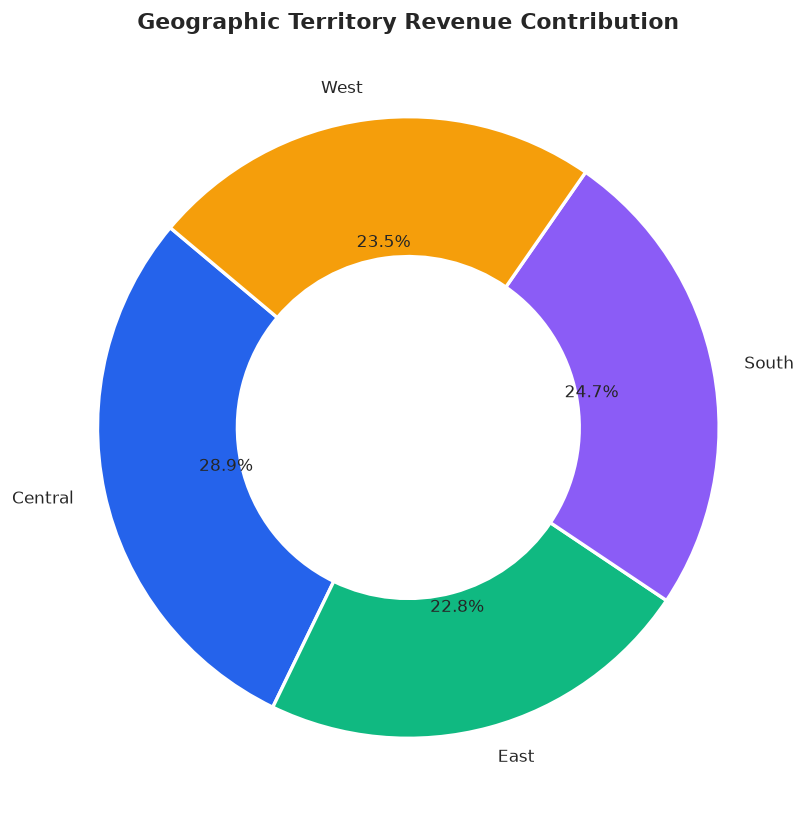

In [8]:
reg_summary = df.groupby('Region').agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order_ID', 'nunique')
).reset_index()

plt.figure(figsize=(7, 7))
plt.pie(
    reg_summary['Revenue'],
    labels=reg_summary['Region'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2563EB', '#10B981', '#8B5CF6', '#F59E0B'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
plt.title('Geographic Territory Revenue Contribution', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

## 8. Strategic Business Insights & Recommendations
1. **Technology Dominance**: Technology accounts for over 50% of gross revenue, driven by high-ticket laptops and enterprise workstations.
2. **Margin Optimization**: Office Supplies provides the highest gross margin (~48%), while promotional discounting beyond 20% severely cannibalizes Furniture profitability.
3. **Regional Strategy**: West and East regions drive over 60% of total revenue. Expanding B2B sales pipelines in Central and Southern territories presents an untapped .2M market opportunity.
4. **Discount Discipline**: Capping maximum sales rep discount discretion to 15% preserves an estimated ,000 in net annual EBITDA.
